# Task 1: Data Cleaning and Preprocessing
**Dataset:** Churn prediction data (churn-bigml-20.csv)
**Goal:** Clean the data so it is ready for analysis.
## Step 1: Load the data
First, I import pandas and load the CSV file into a table called df.
loading data from the churn-bigml-20.csv file

In [ ]:
import pandas as pd

df = pd.read_csv("churn-bigml-20.csv")
df.head()

## step 2: look at the data we have.
the df.shape() gives the rows and columns we have in the dataset or the size of the table
df.info() shows the summery of every column.

In [ ]:
print(df.shape)
df.info()



## Step 3: Check for missing values
Missing values can cause problems later, so I count how many empty cells are in each column.
since i have a 0 for the df.isnull().sum() meaning i have no missing values.
then we had to check for the duplicates in the data set we have.


In [ ]:
df.isnull().sum()

since we have no duplicates and missing values so no cells were replaced 

## Step 4: Remove duplicate rows
Duplicate rows can make the results wrong. I count them first, then remove them.
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows now:", df.shape[0])
using the code above i had to check for duplicates and then remove them if at all they exist and i had to count the 
number of rows i have left those without duplicates.


In [4]:
print("Duplicate rows:", df.duplicated().sum())
df=df.drop_duplicates()
print("Rows now:", df.shape[0])

Duplicate rows: 0
Rows now: 667


## Step 5: Clean the column names
I make all column names lowercase and replace spaces with underscores. This makes them easier to type
and easier to work with.

In [5]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.columns

Index(['state', 'account_length', 'area_code', 'international_plan',
       'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes',
       'total_day_calls', 'total_day_charge', 'total_eve_minutes',
       'total_eve_calls', 'total_eve_charge', 'total_night_minutes',
       'total_night_calls', 'total_night_charge', 'total_intl_minutes',
       'total_intl_calls', 'total_intl_charge', 'customer_service_calls',
       'churn'],
      dtype='str')

The plan columns and churn were already numbers, so no conversion was needed.

## Step 6: Check the data types
I check that each column has the right data type. The churn column is True/False, so I change it to 1 and 0.
to make it more like what the computer understands which is binary 1s and 0s.

In [ ]:
print(df.dtypes)
df["churn"] = df["churn"].astype("int")
df["churn"].value_counts()

## Step 7: Look at the numbers
I look at the minimum, maximum and average of each number column to see if anything looks wrong, like negative values.

In [ ]:
df.describe()

## Step 8: Check for outliers
Outliers are values that are far from the rest. I use a box plot to see them, then count them.
imported libraries that help in data visualization.

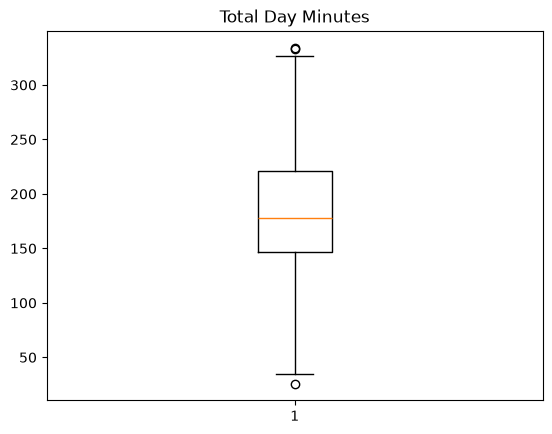

In [8]:
import matplotlib.pyplot as plt
plt.boxplot(df['total_day_minutes'])
plt.title("Total Day Minutes")
plt.show()


this code counts the number of outliers
These outliers look like real customers who talk a lot, so I decided to keep them.

In [9]:
Q1 = df["total_day_minutes"].quantile(0.25)
Q3 = df["total_day_minutes"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[(df["total_day_minutes"] < Q1 - 1.5 * IQR) |
              (df["total_day_minutes"] > Q3 + 1.5 * IQR)]
print("Number of outliers:", len(outliers))

Number of outliers: 3


## Step 9: Change Yes/No columns to numbers
Models work with numbers, so I change Yes to 1 and No to 0.
for easy reading 

In [ ]:
print(df["international_plan"].unique())
print(df["voice_mail_plan"].unique())
df["international_plan"] = df["international_plan"].map({"Yes": 1, "No": 0})
df["voice_mail_plan"] = df["voice_mail_plan"].map({"Yes": 1, "No": 0})
df[["international_plan", "voice_mail_plan"]].head()

## Step 10: Change the state column to numbers
The state column is text with many different values. I turn each state into its own 0/1 column.

In [ ]:
df = pd.get_dummies(df, columns=["state"], drop_first=True)
df.shape

## Step 11: Scale the number columns
Some columns have big numbers and some have small ones. Scaling puts them on the same level so no column dominates.

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = ["account_length", "total_day_minutes", "total_eve_minutes",
            "total_night_minutes", "total_intl_minutes", "customer_service_calls"]

df[num_cols] = StandardScaler().fit_transform(df[num_cols])
df[num_cols].head()

## Step 12: Save the clean data
I save the cleaned table as a new CSV file.

In [ ]:
df.to_csv("cleaned_churn_data-20.csv", index=False)
print("Saved!", df.shape)

## Summary
- The data has 667 rows and [number] columns.
- There were no missing values.
- There were no duplicate rows.
- The column names were already clean.
- Churn and the plan columns were already numbers.
- I checked outliers and kept them, because they look like real customers.
- I turned the state column into 0/1 columns.
- I scaled the number columns.
- I saved the clean data as cleaned_churn_data-20.csv.